<a href="https://colab.research.google.com/github/lilianzlettuce/mat201a-media-signal-proc/blob/main/HW1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Homework 1

**Due 2026-10-06 @ 23:59 PST**

Study _Application of raster scanning method to image sonification, sound visualization, sound analysis and synthesis_ by Yeo & Berger from the Conference on Digital Audio Effects (DaFX) ~ find it here: <https://www.dafx.de/paper-archive>

Now use your favorite LLM to help you prepare a Jupyter/IPython Notebook that illustrates the techniques presented in the paper. First generate the 2D images shown in figure 3 and obtain your own replacements for the images in figure 4. Size all these images appropriately and remember they should be grayscale (0, 255). Next, use the papers technique to generate _sound files_ from these images. Make sure these are audible in your notebook. Next, as mentioned in section 3.3 "Effects of Visual Filters", regenerate sounds from the images _after they have been blurred and/or sharpened_. Now, cleverly choose several sounds to become images using the technique in the paper. You may record the sounds youself or use freesound.org. Most important is the _length_ of the sound. The number of samples will be the number of pixels, so not too many, please. Cleverly choose the width of the rastrograms you produce to approximately match the fundamental frequency of the sound they come from. Now, regenerate the rastrograms from your sounds _after they have been filtered_. Consider low-pass and high-pass filters for the sounds. The point is to show the technique used to produce sound from image and then to produce image from sound. Then to show (visually) the result of sound effects (lowpass, highpass, etc) and to hear (sonically) the result of image effects (blur, sharpen, etc).

Also consider _Voice of Sisyphus: an Image Sonification Multimedia Installation_ by McGee, Dickinson, and Legrady. Find it here: <https://lifeorange.com/writing/McGee_ICAD_2012.pdf>

Run your notebook on colab.research.google.com and share the notebook with <yerkes@ucsb.edu>. Email <yerkes@ucsb.edu> a link to the notebook and make sure I have read access.

In [ ]:
# Set up and import stuff

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio
from PIL import Image
from IPython.display import display
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

fs = 48000                   # sample rate: samples per second
N = fs                       # we'll make 1-second signals, so N samples
t = np.arange(N) / fs        # the time of each sample, in seconds: 0, 1/fs, 2/fs, ...

print(f"{N} samples")
print(f"first few sample times: {t[:4]}")
print(f"last sample time: {t[-1]:.6f} s")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
48000 samples
first few sample times: [0.00000000e+00 2.08333333e-05 4.16666667e-05 6.25000000e-05]
last sample time: 0.999979 s


In [ ]:
# Helper functions from class

# Plot time domain graph
def show_time(x, ms=10, title=""):
    n = int(fs * ms / 1000)                     # how many samples fit in `ms` milliseconds
    plt.figure(figsize=(10, 2.5))
    plt.plot(t[:n] * 1000, x[:n])
    plt.xlabel("time (ms)")
    plt.ylabel("amplitude")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# Plot frequency domain graph
def show_freq(x, fmin=0, fmax=5000, title="", db=False):
    X = np.fft.fft(x)                           # the DFT: N complex numbers
    mag = np.abs(X) / (len(x) / 2)              # magnitude, scaled so a sine of amplitude A shows height A
    freqs = np.fft.fftfreq(len(x), 1 / fs)      # the frequency (Hz) that each bin represents
    keep = (freqs >= fmin) & (freqs <= fmax)    # only plot fmin .. fmax (we'll see why the rest is a mirror)
    plt.figure(figsize=(10, 2.5))
    if db:
        plt.plot(freqs[keep], 20 * np.log10(mag[keep] + 1e-12))
        plt.ylabel("magnitude (dB)")
        plt.ylim(-100, 5)
    else:
        nonzero = mag[keep] > 1e-9                # bins that are numerically zero are left as the baseline
        plt.stem(freqs[keep][nonzero], mag[keep][nonzero], basefmt=" ")
        plt.axhline(0, color="k", lw=0.8)
        plt.xlim(fmin, fmax)
        plt.ylabel("magnitude")
    plt.xlabel("frequency (Hz)")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# Play audio from waveform
def play(x):
    x = 0.5 * x / np.max(np.abs(x) + 1e-12)     # scale to half volume
    return Audio(x, rate=fs)

# Sawtooth waveform creation
def bl_saw(f0, K):
    '''band-limited sawtooth: the first K harmonics of f0'''
    x = np.zeros(N)
    for k in range(1, K + 1):
        x += (-1) ** (k + 1) / k * np.sin(2 * np.pi * k * f0 * t)
    return 2 / np.pi * x

# Map value from one range to another
def map(val, range1_min, range1_max, range2_min, range2_max):
  range1 = range1_max - range1_min
  range2 = range2_max - range2_min
  ratio = (val - range1_min) / range1
  mapped_val = range2_min + (ratio * range2)
  return mapped_val

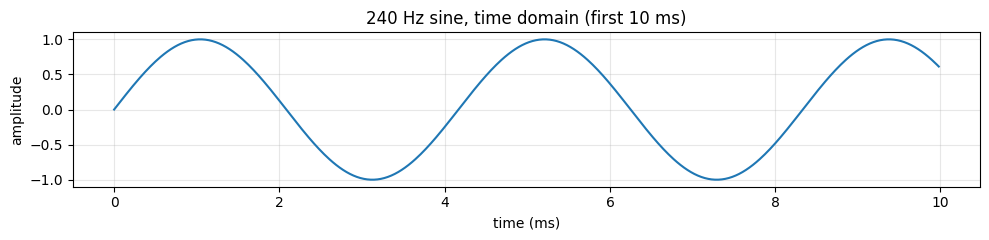

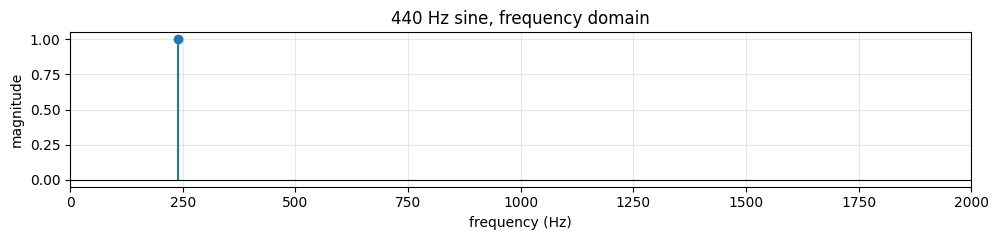

In [ ]:
# Create sine wave
A = 1.0
f = 240.0                                   # 440 Hz = concert A
phi = 0.0
sine_wave = A * np.sin(2 * np.pi * f * t + phi)
sine_wave
show_time(sine_wave, ms=10, title="240 Hz sine, time domain (first 10 ms)")
show_freq(sine_wave, fmax=2000, title="440 Hz sine, frequency domain")
play(sine_wave)

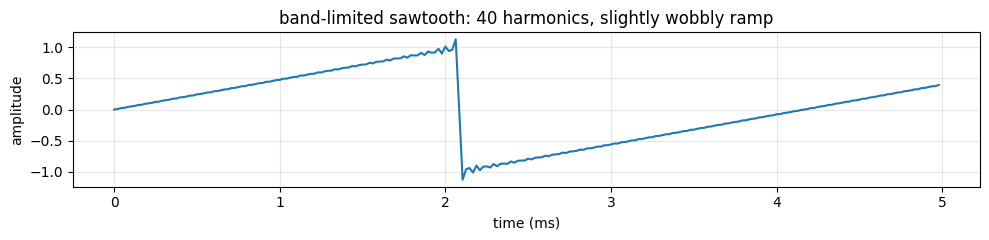

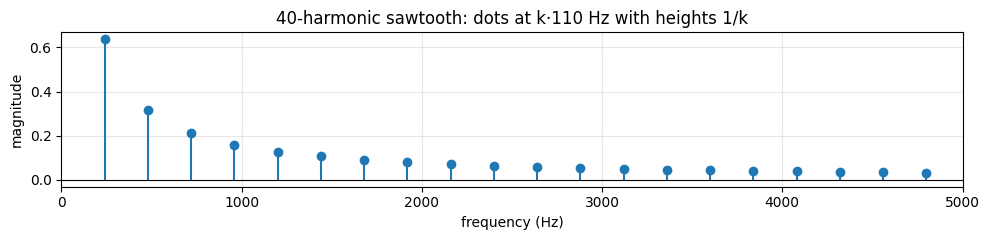

In [ ]:
# Create sawtooth wave
sawtooth_wave = bl_saw(240, 80)
show_time(sawtooth_wave, ms=5, title=f"band-limited sawtooth: {40} harmonics, slightly wobbly ramp")
show_freq(sawtooth_wave, fmax=5000, title="40-harmonic sawtooth: dots at k·110 Hz with heights 1/k")
play(sawtooth_wave)    # forty: a sawtooth

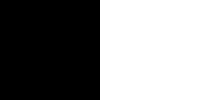

In [ ]:
# Image creation in NumPy example

# Create 3D matrix (100x200 pixels, 3 color channels for RGB)
# Values range from 0 to 255, dtype must be np.uint8
matrix = np.zeros([100, 200, 3], dtype=np.uint8)
matrix[:, :100] = [0]     # left side black
matrix[:, 100:] = [255]     # right side white

# Convert NumPy matrix to PIL Image
img = Image.fromarray(matrix)

# Save or display image
# img.save('output.png')
img

## First generate the 2D images shown in figure 3

Image dimensions: (240, 200)


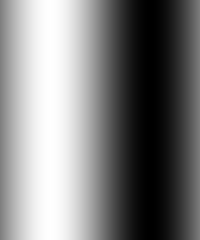

In [ ]:
# Sine wave
mapped_sine_wave = map(sine_wave, -A, A, 0, 255)
mapped_sine_wave = mapped_sine_wave.reshape(-1, int(fs / f)) # 240 rows, 200 cols
print(f'Image dimensions: {mapped_sine_wave.shape}')

# Convert NumPy matrix to PIL Image
img = Image.fromarray(mapped_sine_wave.astype(np.uint8))
img


Image dimensions: (240, 200)


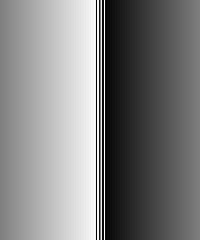

In [ ]:
# Sawtooth wave

mapped_sawtooth_wave = map(sawtooth_wave, -A, A, 0, 255)
mapped_sawtooth_wave = mapped_sawtooth_wave.reshape(-1, int(fs / f)) # 240 rows, 200 cols
print(f'Image dimensions: {mapped_sawtooth_wave.shape}')

# Convert NumPy matrix to PIL Image
img = Image.fromarray(mapped_sawtooth_wave.astype(np.uint8))
img


Image dimensions: (240, 200)


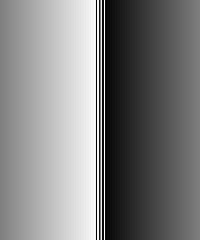

In [ ]:
# Sawtooth wave (unaligned)

mapped_sawtooth_wave = map(sawtooth_wave, -A, A, 0, 255)
mapped_sawtooth_wave = mapped_sawtooth_wave.reshape(-1, int(fs / f)) # 240 rows, 200 cols
print(f'Image dimensions: {mapped_sawtooth_wave.shape}')

# Convert NumPy matrix to PIL Image
img = Image.fromarray(mapped_sawtooth_wave.astype(np.uint8))
img


Image dimensions: (240, 200)


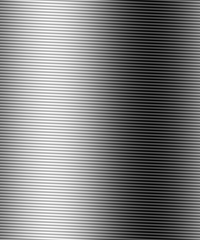

In [ ]:
# Visualize two added sine waves
x1 = 1.0 * np.sin(2 * np.pi * 240 * t)
x2 = 0.5 * np.sin(2 * np.pi * 640 * t)
added_sine_wave = x1 + x2

# Sine wave
mapped_sine_wave = map(added_sine_wave, -1.5, 1.5, 0, 255)
mapped_sine_wave = mapped_sine_wave.reshape(-1, 200) # 240 rows, 200 cols
print(f'Image dimensions: {mapped_sine_wave.shape}')

# Convert NumPy matrix to PIL Image
img = Image.fromarray(mapped_sine_wave.astype(np.uint8))
img

## Obtain your own replacements for the images in figure 4
Size all these images appropriately and remember they should be grayscale (0, 255). Next, use the papers technique to generate sound files from these images. Make sure these are audible in your notebook.

(400, 300, 3)


array([[196, 202, 189, ..., 226, 226, 225],
       [199, 202, 195, ..., 227, 226, 225],
       [195, 197, 197, ..., 227, 227, 226],
       ...,
       [ 52,  50,  48, ..., 148, 147, 146],
       [ 54,  55,  51, ..., 147, 147, 146],
       [ 57,  59,  54, ..., 147, 146, 146]], dtype=uint8)
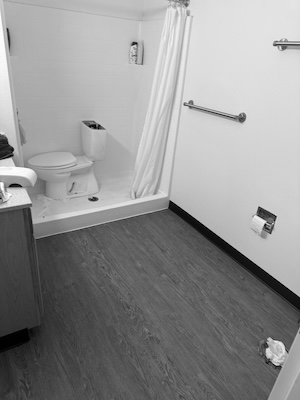

(120000,)


In [ ]:
# Converts image file into audio
def image_to_sound(img_name):
  # Load image from drive and convert it into NumPy array
  img_path = f'/content/drive/MyDrive/MAT 201A - Media Signal Processing/assets/img/{img_name}'
  img = np.array(Image.open(img_path))
  print(img.shape)  # (109, 100, 3) -> height, width, RGB

  # Convert to grayscale
  # Apply the dot product across the color channel axis
  grayscale_weights = [0.299, 0.587, 0.114]
  img = np.dot(img[..., :3], grayscale_weights).astype(np.uint8)
  display(img)

  # Convert image to sound
  img_1D = img.reshape(-1)
  print(img_1D.shape)

  return img_1D

# Image 1
toilet_img = 'toilet.jpg'
toilet_sound = image_to_sound(toilet_img)
play(toilet_sound)

(500, 500, 3)


array([[253, 255, 248, ..., 255, 255, 255],
       [255, 247, 250, ..., 255, 255, 255],
       [250, 248, 253, ..., 255, 255, 255],
       ...,
       [255, 255, 255, ..., 253, 247, 253],
       [255, 255, 255, ..., 252, 248, 252],
       [255, 255, 255, ..., 248, 253, 253]], dtype=uint8)
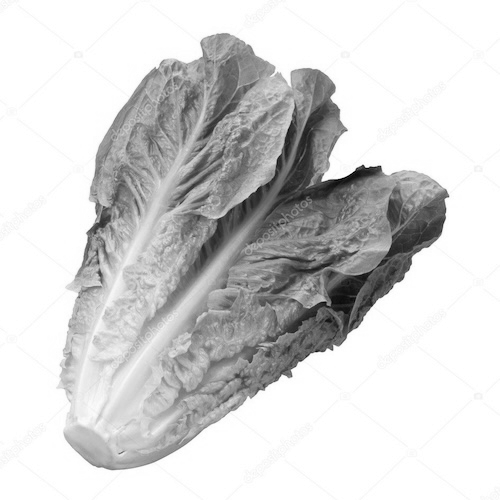

(250000,)


In [ ]:
# Image 2
lettuce_img = 'lettuce_500x500.jpg'
lettuce_sound = image_to_sound(lettuce_img)
play(lettuce_sound)

(315, 200, 3)


array([[176, 180, 182, ...,  65,  64,  72],
       [179, 180, 180, ...,  70,  69,  67],
       [177, 178, 179, ...,  66,  57,  45],
       ...,
       [ 10,  12,   8, ..., 150, 150, 149],
       [ 10,  12,   8, ..., 138, 141, 141],
       [ 10,  11,   9, ..., 131, 132, 132]], dtype=uint8)
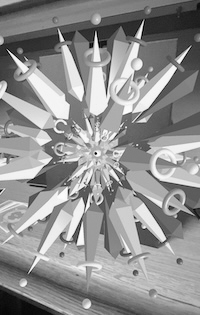

(63000,)


In [ ]:
# Image 3
sne_img = 'sne.jpg'
sne_sound = image_to_sound(sne_img)
play(sne_sound)

# Next, as mentioned in section 3.3 "Effects of Visual Filters", regenerate sounds from the images after they have been blurred and/or sharpened

(400, 300, 3)


array([[190, 188, 185, ..., 228, 227, 227],
       [191, 189, 186, ..., 228, 227, 227],
       [193, 191, 187, ..., 228, 227, 227],
       ...,
       [ 52,  52,  52, ..., 146, 146, 146],
       [ 53,  53,  53, ..., 146, 146, 146],
       [ 54,  54,  55, ..., 147, 146, 146]], dtype=uint8)
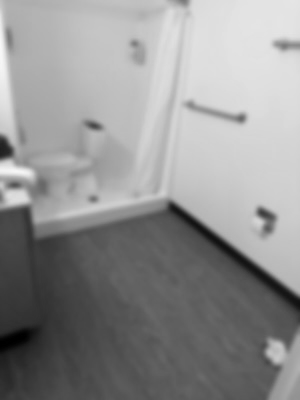

(120000,)


In [ ]:
# Image 1
toilet_img_blurred = 'toilet_blurred.jpg'
toilet_blurred_sound = image_to_sound(toilet_img_blurred)
play(toilet_blurred_sound)

(500, 500, 3)


array([[247, 255, 232, ..., 255, 255, 255],
       [253, 208, 245, ..., 255, 255, 255],
       [250, 234, 255, ..., 255, 255, 255],
       ...,
       [255, 255, 255, ..., 255, 213, 253],
       [255, 255, 255, ..., 252, 229, 250],
       [255, 255, 255, ..., 237, 252, 255]], dtype=uint8)
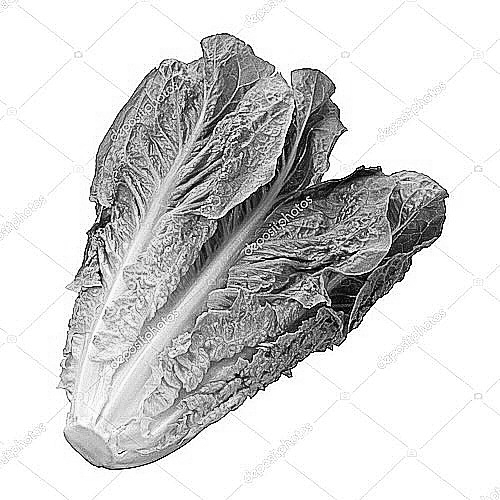

(250000,)


In [ ]:
# Image 2
lettuce_img_blurred = 'lettuce_sharpened.jpg'
lettuce_blurred_sound = image_to_sound(lettuce_img_blurred)
play(lettuce_blurred_sound)

(315, 200, 3)


array([[178, 178, 178, ...,  56,  55,  53],
       [173, 172, 172, ...,  56,  53,  51],
       [166, 166, 165, ...,  53,  50,  48],
       ...,
       [ 17,  17,  15, ..., 145, 147, 147],
       [ 17,  17,  15, ..., 142, 142, 142],
       [ 17,  17,  15, ..., 138, 139, 140]], dtype=uint8)
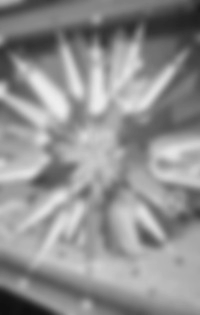

(63000,)


In [ ]:
# Image 3
sne_img_filtered = 'sne_blurred.jpg'
sne_filtered_sound = image_to_sound(sne_img_filtered)
play(sne_filtered_sound)

## Now, cleverly choose several sounds to become images using the technique in the paper.
You may record the sounds youself or use freesound.org.
Most important is the length of the sound. The number of samples will be the number of pixels, so not too many, please. Cleverly choose the width of the rastrograms you produce to approximately match the fundamental frequency of the sound they come from.


In [ ]:
import librosa
from scipy import signal

# Convert sound file to image
def sound_to_image(audio_name, cols = 200, fs = 48000, filter = None):
  # Load sound from drive and convert it into NumPy array
  audio_path = f'/content/drive/MyDrive/MAT 201A - Media Signal Processing/assets/sound/{audio_name}'
  audio_array, sample_rate = librosa.load(audio_path, sr=fs, mono=True)

  print(audio_array)         # NumPy array of samples
  print(audio_array.shape)   # (number_of_samples,)
  print(sample_rate)         # Integer sample rate (e.g., 44100)

  # Filter audio clip if filter provided
  if filter is not None :
      audio_array = signal.sosfilt(filter, audio_array)

  # Map samples to image RGB range
  mapped_audio_array = map(audio_array, -1, 1, 0, 255)

  # Set num cols and calculate how many full rows fit
  rows = len(mapped_audio_array) // cols

  # Reshape after slicing to drop the leftover samples
  audio_img_array = mapped_audio_array[: rows * cols].reshape(rows, cols)
  print(f'Image dimensions: {audio_img_array.shape}')

  # Convert NumPy matrix to PIL Image
  audio_img = Image.fromarray(audio_img_array.astype(np.uint8))
  display(audio_img)

  return Audio(audio_path)

[-5.0437171e-05 -5.2484684e-06  6.7800283e-05 ... -7.1819499e-04
 -5.1776320e-04 -2.3525208e-04]
(49740,)
48000
Image dimensions: (829, 60)


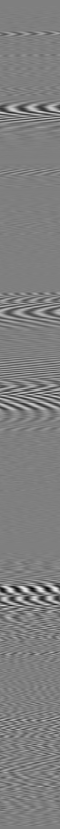

In [ ]:
# Sound 1

bird_sound = "190.mp3" # fs = 16000, dominant freq = 3135 Hz
sound_to_image(bird_sound, 60) #60

[ 0.0000000e+00  3.5874945e-10  2.6359359e-10 ... -3.2752714e-06
 -1.9648885e-05 -1.8030551e-06]
(215424,)
24000
Image dimensions: (448, 480)


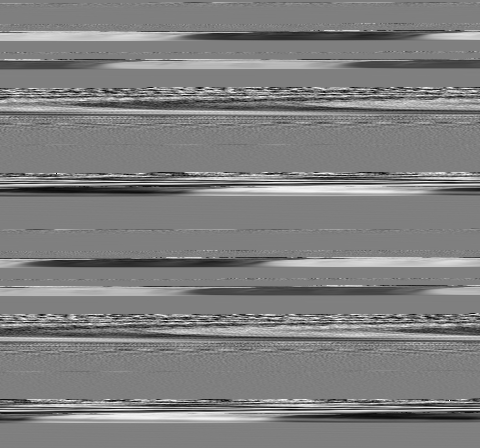

In [ ]:
# Sound 2

bird_sound = "beat.mp3" # fs = 24000, dominant freq = 50Hz
sound_to_image(bird_sound, 24000//50, None)

[0.0000000e+00 1.7705104e-10 6.1249339e-11 ... 0.0000000e+00 0.0000000e+00
 0.0000000e+00]
(248832,)
48000
Image dimensions: (259, 960)


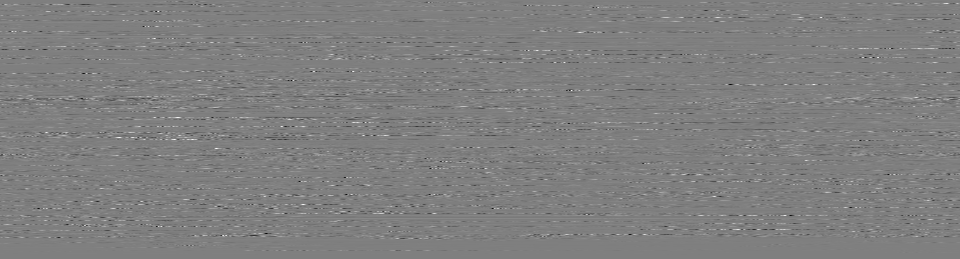

In [ ]:
# Sound 3

bird_sound = "creaking-rope.mp3" # fs = 48000, dominant freq = 50Hz ??
sound_to_image(bird_sound, 48000//50, None) # 500

## Now, regenerate the rastrograms from your sounds after they have been filtered.
Consider low-pass and high-pass filters for the sounds. The point is to show the technique used to produce sound from image and then to produce image from sound. Then to show (visually) the result of sound effects (lowpass, highpass, etc) and to hear (sonically) the result of image effects (blur, sharpen, etc).


In [ ]:
# Set up filters
b, a = signal.iirfilter(17, [2*np.pi*50, 2*np.pi*200], rs=60,  btype='band', analog=True, ftype='cheby2')
w, h = signal.freqs(b, a, 1000)

# Filter specifications
fs = 1000.0       # Sampling frequency (Hz)
order = 4         # Filter order

# High-pass filter with sos output
highPassFilter = signal.iirfilter(
    N=order,
    Wn=5, # cutoff
    btype='highpass',
    ftype='butter',
    output='sos',
    fs=fs
)

# Low-pass filter with sos output
lowPassFilter = signal.iirfilter(
    N=order,
    Wn=50,
    btype='lowpass',
    ftype='butter',
    output='sos',
    fs=fs
)

[-5.0437171e-05 -5.2484684e-06  6.7800283e-05 ... -7.1819499e-04
 -5.1776320e-04 -2.3525208e-04]
(49740,)
48000
Image dimensions: (829, 60)


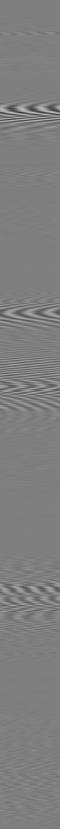

In [ ]:
# Sound 1, low pass filtered

bird_sound = "190.mp3" # fs = 16000, dominant freq = 3135 Hz
sound_to_image(bird_sound, 60, 48000, lowPassFilter) #60


[ 0.0000000e+00  3.5874945e-10  2.6359359e-10 ... -3.2752714e-06
 -1.9648885e-05 -1.8030551e-06]
(215424,)
24000
Image dimensions: (448, 480)


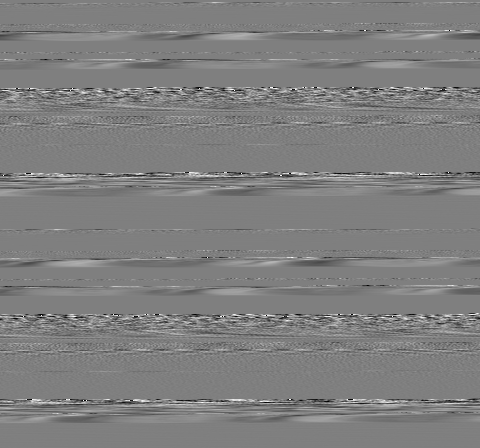

In [ ]:
# Sound 2, high pass filtered

bird_sound = "beat.mp3" # fs = 24000, dominant freq = 50Hz
sound_to_image(bird_sound, 24000//50, None, highPassFilter)

[0.0000000e+00 1.7705104e-10 6.1249339e-11 ... 0.0000000e+00 0.0000000e+00
 0.0000000e+00]
(248832,)
48000
Image dimensions: (259, 960)


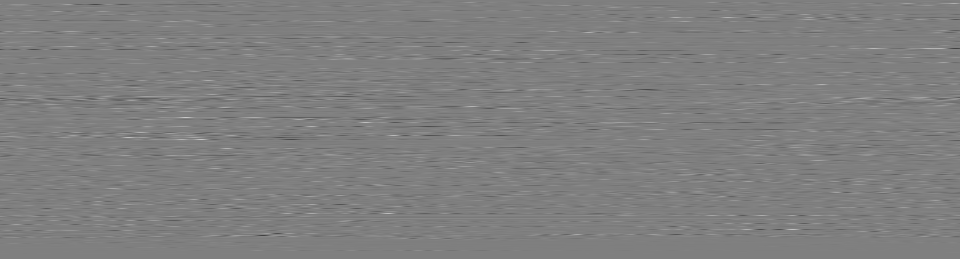

In [ ]:
# Sound 3, low pass filtered

bird_sound = "creaking-rope.mp3" # fs = 48000, dominant freq = 50Hz ??
sound_to_image(bird_sound, 48000//50, None, lowPassFilter) # 500